# CDISC SDTM & ADaM walkthrough: one subject, raw -> SDTM -> ADaM

Run the pipeline first (`source("run_all.R")` from the repo root). This notebook then follows **one Phase III subject**
through every layer, so you can *see* each CDISC rule applied. Companion reading: `docs/CDISC_SDTM_ADaM_Guide.md`.

| Step | What you look at | CDISC lesson |
|---|---|---|
| 1 | Raw source inventory | Data arrive from 7 systems in 7 formats |
| 2 | Demographics + IXRS -> DM / SUPPDM | DM is assembled; non-standard variables go to SUPP-- |
| 3 | Central lab pipe file -> LB | Vendor keys, ORRES vs STRESN, SI units |
| 4 | Biomarker lab -> LB | <LLOQ and QC failures (LBSTAT/LBREASND) |
| 5 | Wide cognitive CRF -> QS | Pivot; CDR-SB is *not* collected so *not* in SDTM |
| 6 | ADSL | Hub: treatment, dates, populations, baseline covariates |
| 7 | ADQS / ADBM | BDS: PARAMCD, AVAL, ABLFL, BASE, CHG, derived parameters |
| 8 | Traceability | SRCDOM/SRCSEQ walk an ADaM value back to SDTM |
| 9 | ADAE partial dates | ASTDT/ASTDTF imputation and TRTEMFL |
| 10 | Results | Figures and headline numbers, all from ADaM |


In [1]:
source("../R/00_setup.R")
options(width = 160, tibble.width = Inf, tibble.print_max = 30)
rawf <- function(...) read_csv(file.path(DIR_RAW, ...), show_col_types = FALSE, col_types = cols(.default = "c"), na = "")
sd   <- function(d) read_csv(file.path(DIR_SDTM, paste0(d, ".csv")), show_col_types = FALSE, col_types = cols(.default = "c"), na = "")
ad   <- function(d) read_csv(file.path(DIR_ADAM, paste0(d, ".csv")), show_col_types = FALSE, guess_max = 1e5, na = "")
SUBJ <- "3001-001"; USUBJ <- paste0("ADBM-301-", SUBJ)

Setup complete. Root: /yemi/cdisc-ad-biomarker-pipeline



## 1. Raw source inventory
Seven source systems; none of them is CDISC.

In [2]:
read_csv(file.path(DIR_RAW, 'RAW_INVENTORY.csv'), show_col_types = FALSE)

file,rows
<chr>,<dbl>
bioanalytical/pk_serum_concentrations.csv,475
biomarker_lab/biomarker_plasma_results.csv,16920
biomarker_lab/biomarker_visit_code_map.csv,13
central_lab/centrallab_safety_results.txt,60255
edc/coding_meddra_ae.csv,53
edc/coding_whodrug_cm.csv,9
edc/edc_adverse_events.csv,2559
edc/edc_cognitive_scales.csv,6695
edc/edc_conmeds.csv,2348


## 2. Demographics: EDC + IXRS -> DM and SUPPDM
Note `Male` -> `M` (controlled terminology), `05-JUN-2023` -> `2023-06-05` (ISO 8601), birth *year* only, and `RFSTDTC` coming from the **first dose** in EX.

In [3]:
rawf("edc", "edc_demographics.csv") %>% filter(SUBJECT == SUBJ, STUDY == "ADBM-301")
rawf("ixrs", "ixrs_randomization.csv") %>% filter(SUBJECT == SUBJ, PROTOCOL == "ADBM301")
sd("dm") %>% filter(USUBJID == USUBJ) %>% select(USUBJID, SUBJID, SITEID, RFSTDTC, RFICDTC, BRTHDTC, AGE, SEX, RACE, ARMCD, ARM, COUNTRY)
sd("suppdm") %>% filter(USUBJID == USUBJ)

STUDY,SUBJECT,SITE_NO,BIRTH_YEAR,AGE_AT_CONSENT,GENDER,RACE,ETHNICITY,CONSENT_DATE
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ADBM-301,3001-001,3001,1943,80,Female,White,Not Hispanic or Latino,17-JUN-2023


PROTOCOL,SUBJECT,RAND_NO,RAND_DATE,TREATMENT_ARM,STRATUM
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ADBM301,3001-001,R15995,2023-07-07,Active,APOE4 NON-CARRIER


USUBJID,SUBJID,SITEID,RFSTDTC,RFICDTC,BRTHDTC,AGE,SEX,RACE,ARMCD,ARM,COUNTRY
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ADBM-301-3001-001,3001-001,3001,2023-07-08,2023-06-17,1943,80,F,WHITE,ACT,ABX-001 1000 mg Q4W,CAN


STUDYID,RDOMAIN,USUBJID,IDVAR,IDVARVAL,QNAM,QLABEL,QVAL,QORIG,QEVAL
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ADBM-301,DM,ADBM-301-3001-001,NA,NA,RANDNO,Randomization Number,R15995,ASSIGNED,NA
ADBM-301,DM,ADBM-301-3001-001,NA,NA,STRATUM,Randomization Stratum,APOE4 NON-CARRIER,ASSIGNED,NA


## 3. Central lab: pipe-delimited vendor file -> LB
The vendor key `ADBM301|3001-001` must be rebuilt into `USUBJID`. Original result/units stay in `LBORRES/LBORRESU`; SI units go to `LBSTRESN/LBSTRESU` (bilirubin mg/dL x 17.1 = umol/L).

In [4]:
lab <- read_delim(file.path(DIR_RAW, "central_lab", "centrallab_safety_results.txt"), delim = "|", show_col_types = FALSE,
                  col_types = cols(.default = "c"), na = "")
lab %>% filter(PATIENT_ID == paste0("ADBM301|", SUBJ), TEST_CODE %in% c("TBIL", "CREA", "NA"), VISIT_DESC == "Wk 13")
sd("lb") %>% filter(USUBJID == USUBJ, LBTESTCD %in% c("BILI", "CREAT", "SODIUM"), VISIT == "WEEK 13") %>%
  select(LBSEQ, LBTESTCD, LBORRES, LBORRESU, LBSTRESC, LBSTRESN, LBSTRESU, LBNRIND, VISIT, LBDTC, LBDY)

ACCESSION,PATIENT_ID,VISIT_DESC,COLLECTION_DATETIME,PANEL,TEST_CODE,TEST_NAME,RESULT,UNITS,REF_LOW,REF_HIGH,FLAG
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ACC00011208,ADBM301|3001-001,Wk 13,2023/10/11 11:06,CHEM,CREA,Creatinine,0.9,mg/dL,0.6,1.3,NA
ACC00011211,ADBM301|3001-001,Wk 13,2023/10/11 11:33,CHEM,NA,Sodium,139,mmol/L,135,145,NA
ACC00011213,ADBM301|3001-001,Wk 13,2023/10/11 11:50,CHEM,TBIL,Total Bilirubin,0.4,mg/dL,0.2,1.2,NA


LBSEQ,LBTESTCD,LBORRES,LBORRESU,LBSTRESC,LBSTRESN,LBSTRESU,LBNRIND,VISIT,LBDTC,LBDY
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
26,BILI,0.4,mg/dL,6.84,6.84,umol/L,NORMAL,WEEK 13,2023-10-11T11:50,96
27,CREAT,0.9,mg/dL,79.58,79.58,umol/L,NORMAL,WEEK 13,2023-10-11T11:06,96
29,SODIUM,139,mmol/L,139,139,mmol/L,NORMAL,WEEK 13,2023-10-11T11:33,96


Note the sodium test code is the string `"NA"`. A careless reader turns it into a missing value. That is why every raw file is read as character with `na = ""`.

## 4. Biomarker lab -> LB (LBCAT = 'BIOMARKER')
Vendor visit codes (V2, V4...) are mapped through a crosswalk. Below-LLOQ and QC-failed samples show the two special cases.

In [5]:
sd("lb") %>% filter(USUBJID == USUBJ, LBCAT == "BIOMARKER") %>%
  select(LBSEQ, LBTESTCD, LBSPEC, LBMETHOD, LBORRES, LBSTRESN, LBLLOQ, LBSTAT, LBREASND, LBBLFL, VISIT, LBDTC)
sd("lb") %>% filter(LBCAT == "BIOMARKER", (grepl("^<", LBORRES) | LBSTAT == "NOT DONE")) %>%
  select(USUBJID, LBTESTCD, LBORRES, LBSTRESC, LBSTRESN, LBLLOQ, LBSTAT, LBREASND) %>% head(6)

LBSEQ,LBTESTCD,LBSPEC,LBMETHOD,LBORRES,LBSTRESN,LBLLOQ,LBSTAT,LBREASND,LBBLFL,VISIT,LBDTC
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
10,AB40,PLASMA,LC-MS/MS,265.86,265.86,20,NA,NA,Y,BASELINE,2023-07-08
11,AB42,PLASMA,LC-MS/MS,24.04,24.04,2,NA,NA,Y,BASELINE,2023-07-08
12,GFAP,PLASMA,IMMUNOASSAY (SIMOA),142.27,142.27,10,NA,NA,Y,BASELINE,2023-07-08
13,NFL,PLASMA,IMMUNOASSAY (SIMOA),18.28,18.28,1.5,NA,NA,Y,BASELINE,2023-07-08
14,PTAU217,PLASMA,LC-MS/MS,0.434,0.434,0.1,NA,NA,Y,BASELINE,2023-07-08
33,AB40,PLASMA,LC-MS/MS,252.09,252.09,20,NA,NA,NA,WEEK 26,2024-01-06
34,AB42,PLASMA,LC-MS/MS,23.47,23.47,2,NA,NA,NA,WEEK 26,2024-01-06
35,GFAP,PLASMA,IMMUNOASSAY (SIMOA),132.08,132.08,10,NA,NA,NA,WEEK 26,2024-01-06
36,NFL,PLASMA,IMMUNOASSAY (SIMOA),15.40,15.4,1.5,NA,NA,NA,WEEK 26,2024-01-06


USUBJID,LBTESTCD,LBORRES,LBSTRESC,LBSTRESN,LBLLOQ,LBSTAT,LBREASND
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ADBM-101-1001-007,PTAU217,NA,NA,NA,0.1,NOT DONE,INSUFFICIENT VOLUME
ADBM-101-1001-010,AB42,NA,NA,NA,2,NOT DONE,RUN QC FAILURE
ADBM-101-1002-003,GFAP,NA,NA,NA,10,NOT DONE,RUN QC FAILURE
ADBM-101-1003-003,PTAU217,NA,NA,NA,0.1,NOT DONE,RUN QC FAILURE
ADBM-101-1003-006,AB42,NA,NA,NA,2,NOT DONE,HEMOLYZED SAMPLE
ADBM-101-1003-012,PTAU217,<0.1,<0.1,NA,0.1,NA,NA


## 5. Cognitive CRF (wide) -> QS (long)
One CRF row becomes nine QS rows. **CDR Sum of Boxes is not on the CRF, so it is not in SDTM.**

In [6]:
rawf("edc", "edc_cognitive_scales.csv") %>% filter(SUBJECT == SUBJ, STUDY == "ADBM-301", VISIT_NAME == "Baseline/Day 1")
sd("qs") %>% filter(USUBJID == USUBJ, VISIT == "BASELINE") %>% select(QSSEQ, QSCAT, QSTESTCD, QSTEST, QSORRES, QSSTRESN, QSBLFL, QSDTC, QSDY)

STUDY,SUBJECT,VISIT_NAME,ASMT_DATE,CDR_MEM,CDR_ORI,CDR_JUD,CDR_COM,CDR_HOM,CDR_PER,CDR_GLOBAL,MMSE_TOT,ADAS13_TOT
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ADBM-301,3001-001,Baseline/Day 1,08-JUL-2023,0.5,0.5,0.5,0.5,0.5,0,0.5,24,13


QSSEQ,QSCAT,QSTESTCD,QSTEST,QSORRES,QSSTRESN,QSBLFL,QSDTC,QSDY
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
10,ADAS-COG 13-ITEM,ADAS13,ADAS-Cog13 - Total Score,13,13,Y,2023-07-08,1
11,CLINICAL DEMENTIA RATING,CDRCARE,CDR - Personal Care,0,0,Y,2023-07-08,1
12,CLINICAL DEMENTIA RATING,CDRCOMM,CDR - Community Affairs,0.5,0.5,Y,2023-07-08,1
13,CLINICAL DEMENTIA RATING,CDRGLOB,CDR - Global Score,0.5,0.5,Y,2023-07-08,1
14,CLINICAL DEMENTIA RATING,CDRHOME,CDR - Home and Hobbies,0.5,0.5,Y,2023-07-08,1
15,CLINICAL DEMENTIA RATING,CDRJUDG,CDR - Judgment and Problem Solving,0.5,0.5,Y,2023-07-08,1
16,CLINICAL DEMENTIA RATING,CDRMEM,CDR - Memory,0.5,0.5,Y,2023-07-08,1
17,CLINICAL DEMENTIA RATING,CDRORIEN,CDR - Orientation,0.5,0.5,Y,2023-07-08,1
18,MINI-MENTAL STATE EXAMINATION,MMSETOT,MMSE - Total Score,24,24,Y,2023-07-08,1


## 6. ADSL: the subject-level hub

In [7]:
ad("adsl") %>% filter(USUBJID == USUBJ) %>% mutate(across(everything(), as.character)) %>%
  pivot_longer(everything(), names_to = "VARIABLE", values_to = "VALUE") %>% print(n = 60)

# A tibble: 51 × 2
   VARIABLE VALUE                 
   <chr>    <chr>                 
 1 STUDYID  ADBM-301              
 2 USUBJID  ADBM-301-3001-001     
 3 SUBJID   3001-001              
 4 SITEID   3001                  
 5 COUNTRY  CAN                   
 6 PHASE    PHASE III             
 7 REGION1  NORTH AMERICA         
 8 AGE      80                    
 9 AGEU     YEARS                 
10 AGEGR1   >=75                  
11 AGEGR1N  3                     
12 SEX      F                     
13 RACE     WHITE                 
14 ETHNIC   NOT HISPANIC OR LATINO
15 ARM      ABX-001 1000 mg Q4W   
16 ARMCD    ACT                   
17 ACTARM   ABX-001 1000 mg Q4W   
18 ACTARMCD ACT                   
19 TRT01P   ABX-001 1000 mg Q4W   
20 TRT01PN  1000                  
21 TRT01A   ABX-001 1000 mg Q4W   
22 TRT01AN  1000                  
23 TRT01PG1 Active                
24 RANDDT   2023-07-07            
25 TRTSDT   2023-07-08            
26 TRTEDT   2024-11-23            
2

## 7. BDS datasets: ADQS (derived CDR-SB) and ADBM (derived Abeta42/40)
`PARAMTYP = 'DERIVED'` marks parameters computed from other parameters.

In [8]:
ad("adqs") %>% filter(USUBJID == USUBJ, PARAMCD == "CDRSB") %>% select(PARAMCD, PARAMTYP, AVISIT, AVISITN, ADT, ADY, AVAL, BASE, CHG, ABLFL, ANL01FL)
ad("adbm") %>% filter(USUBJID == USUBJ, PARAMCD %in% c("PTAU217", "AB4240")) %>%
  select(PARAMCD, PARAMTYP, AVISIT, AVAL, BLQFL, BASE, PCHG, ABLFL, SRCDOM, SRCSEQ)

PARAMCD,PARAMTYP,AVISIT,AVISITN,ADT,ADY,AVAL,BASE,CHG,ABLFL,ANL01FL
<chr>,<chr>,<chr>,<dbl>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>
CDRSB,DERIVED,SCREENING,-1,2023-06-12,-26,3.0,2.5,NA,NA,NA
CDRSB,DERIVED,BASELINE,0,2023-07-08,1,2.5,2.5,NA,Y,Y
CDRSB,DERIVED,WEEK 13,13,2023-10-11,96,4.0,2.5,1.5,NA,Y
CDRSB,DERIVED,WEEK 26,26,2024-01-06,183,2.5,2.5,0.0,NA,Y
CDRSB,DERIVED,WEEK 39,39,2024-04-04,272,4.0,2.5,1.5,NA,Y
CDRSB,DERIVED,WEEK 52,52,2024-07-16,375,3.0,2.5,0.5,NA,Y
CDRSB,DERIVED,WEEK 65,65,2024-10-05,456,4.5,2.5,2.0,NA,Y
CDRSB,DERIVED,WEEK 78,78,2025-01-02,545,3.5,2.5,1.0,NA,Y


PARAMCD,PARAMTYP,AVISIT,AVAL,BLQFL,BASE,PCHG,ABLFL,SRCDOM,SRCSEQ
<chr>,<chr>,<chr>,<dbl>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<dbl>
AB4240,DERIVED,BASELINE,0.09042,NA,0.09042,NA,Y,LB,NA
AB4240,DERIVED,WEEK 26,0.09310,NA,0.09042,2.963946,NA,LB,NA
AB4240,DERIVED,WEEK 52,0.09955,NA,0.09042,10.097324,NA,LB,NA
AB4240,DERIVED,WEEK 78,0.09889,NA,0.09042,9.367397,NA,LB,NA
PTAU217,NA,BASELINE,0.43400,NA,0.43400,NA,Y,LB,14
PTAU217,NA,WEEK 26,0.30300,NA,0.43400,-30.184332,NA,LB,37
PTAU217,NA,WEEK 52,0.29700,NA,0.43400,-31.566820,NA,LB,60
PTAU217,NA,WEEK 78,0.34900,NA,0.43400,-19.585253,NA,LB,83


## 8. Traceability: walk an ADaM value back to SDTM with SRCSEQ

In [9]:
rec <- ad("adqs") %>% filter(USUBJID == USUBJ, PARAMCD == "MMSE", AVISITN == 78)
rec %>% select(USUBJID, PARAMCD, AVISIT, AVAL, SRCDOM, SRCVAR, SRCSEQ)
sd("qs") %>% filter(USUBJID == USUBJ, QSSEQ == as.character(rec$SRCSEQ)) %>% select(USUBJID, QSSEQ, QSTESTCD, QSORRES, QSSTRESN, VISIT, QSDTC)

USUBJID,PARAMCD,AVISIT,AVAL,SRCDOM,SRCVAR,SRCSEQ
<chr>,<chr>,<chr>,<dbl>,<chr>,<chr>,<dbl>
ADBM-301-3001-001,MMSE,WEEK 78,25,QS,QSSTRESN,72


USUBJID,QSSEQ,QSTESTCD,QSORRES,QSSTRESN,VISIT,QSDTC
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
ADBM-301-3001-001,72,MMSETOT,25,25,WEEK 78,2025-01-02


## 9. ADAE: partial dates and treatment-emergence
SDTM keeps `AESTDTC = '2024-06'`. ADaM imputes `ASTDT` and records how in `ASTDTF`.

In [10]:
ad("adae") %>% filter(!is.na(ASTDTF)) %>% select(USUBJID, AEDECOD, AESTDTC, ASTDT, ASTDTF, TRTSDT, TRTEMFL) %>% head(8)
ad("adae") %>% filter(TRTEMFL == "Y", CQ01NAM == "ARIA-E") %>% count(STUDYID, TRT01PG1, APOE4N)

USUBJID,AEDECOD,AESTDTC,ASTDT,ASTDTF,TRTSDT,TRTEMFL
<chr>,<chr>,<chr>,<date>,<chr>,<date>,<chr>
ADBM-101-1004-004,Cough,2022-11,2022-11-01,D,2022-08-07,Y
ADBM-201-2001-001,Diarrhoea,2024-02,2024-02-01,D,2023-03-07,Y
ADBM-201-2002-004,Headache,2023-01,2023-01-16,D,2023-01-16,Y
ADBM-201-2003-005,Anxiety,2023-12,2023-12-01,D,2023-02-16,Y
ADBM-201-2004-003,Fatigue,2023-05,2023-05-01,D,2022-12-20,Y
ADBM-201-2004-022,Infusion related reaction,2023-11,2023-11-01,D,2023-09-24,Y
ADBM-201-2005-008,Insomnia,2024-03,2024-03-01,D,2023-06-26,Y
ADBM-201-2005-010,Arthralgia,2023-11,2023-11-01,D,2023-07-21,Y


STUDYID,TRT01PG1,APOE4N,n
<chr>,<chr>,<dbl>,<int>
ADBM-201,High Dose,0,1
ADBM-201,High Dose,1,1
ADBM-201,Low Dose,1,1
ADBM-301,Active,0,14
ADBM-301,Active,1,19
ADBM-301,Active,2,8
ADBM-301,Placebo,0,1
ADBM-301,Placebo,1,3
ADBM-301,Placebo,2,2


## 10. Results (every number below comes from ADaM)

{
  "phase1": {
    "cmax_slope": 1.01,
    "cmax_ci90": [0.94, 1.09],
    "auc_slope": 1,
    "thalf_days_median": 28.3
  },
  "phase2": {
    "ptau_pct_vs_pbo_high": -42.3,
    "ptau_pct_vs_pbo_low": -22.4,
    "p_high": "<0.001"
  },
  "phase3": {
    "cdrsb_diff_wk78": -0.5,
    "cdrsb_ci95": [-0.73, -0.27],
    "cdrsb_p": "<0.001",
    "cdrsb_pct_slowing": 28.5,
    "adas13_diff_wk78": -1.99,
    "adas13_p": "<0.001",
    "n_efficacy": 583
  },
  "pet": {
    "ph3_active_cl_change": -49.1,
    "ph3_active_amyneg_pct": 49.3
  },
  "aria": {
    "active_e4hom_pct": 18.9,
    "active_noncarrier_pct": 6.8,
    "placebo_pct": 1.7,
    "hr_active": 6.6
  },
  "phase4": {
    "auc_ptau217": 0.927,
    "auc_ci": [0.898, 0.955],
    "auc_ab4240": 0.904,
    "youden_cut": 0.298,
    "sens": 0.772,
    "spec": 0.917,
    "intermediate_pct": 29.5,
    "accuracy_outside": 93.3,
    "n": 298,
    "rho_all": 0.8
  },
  "surrogacy": {
    "r": 0.24,
    "pte_pct": 45
  },
  "safety": {
    "hys_l

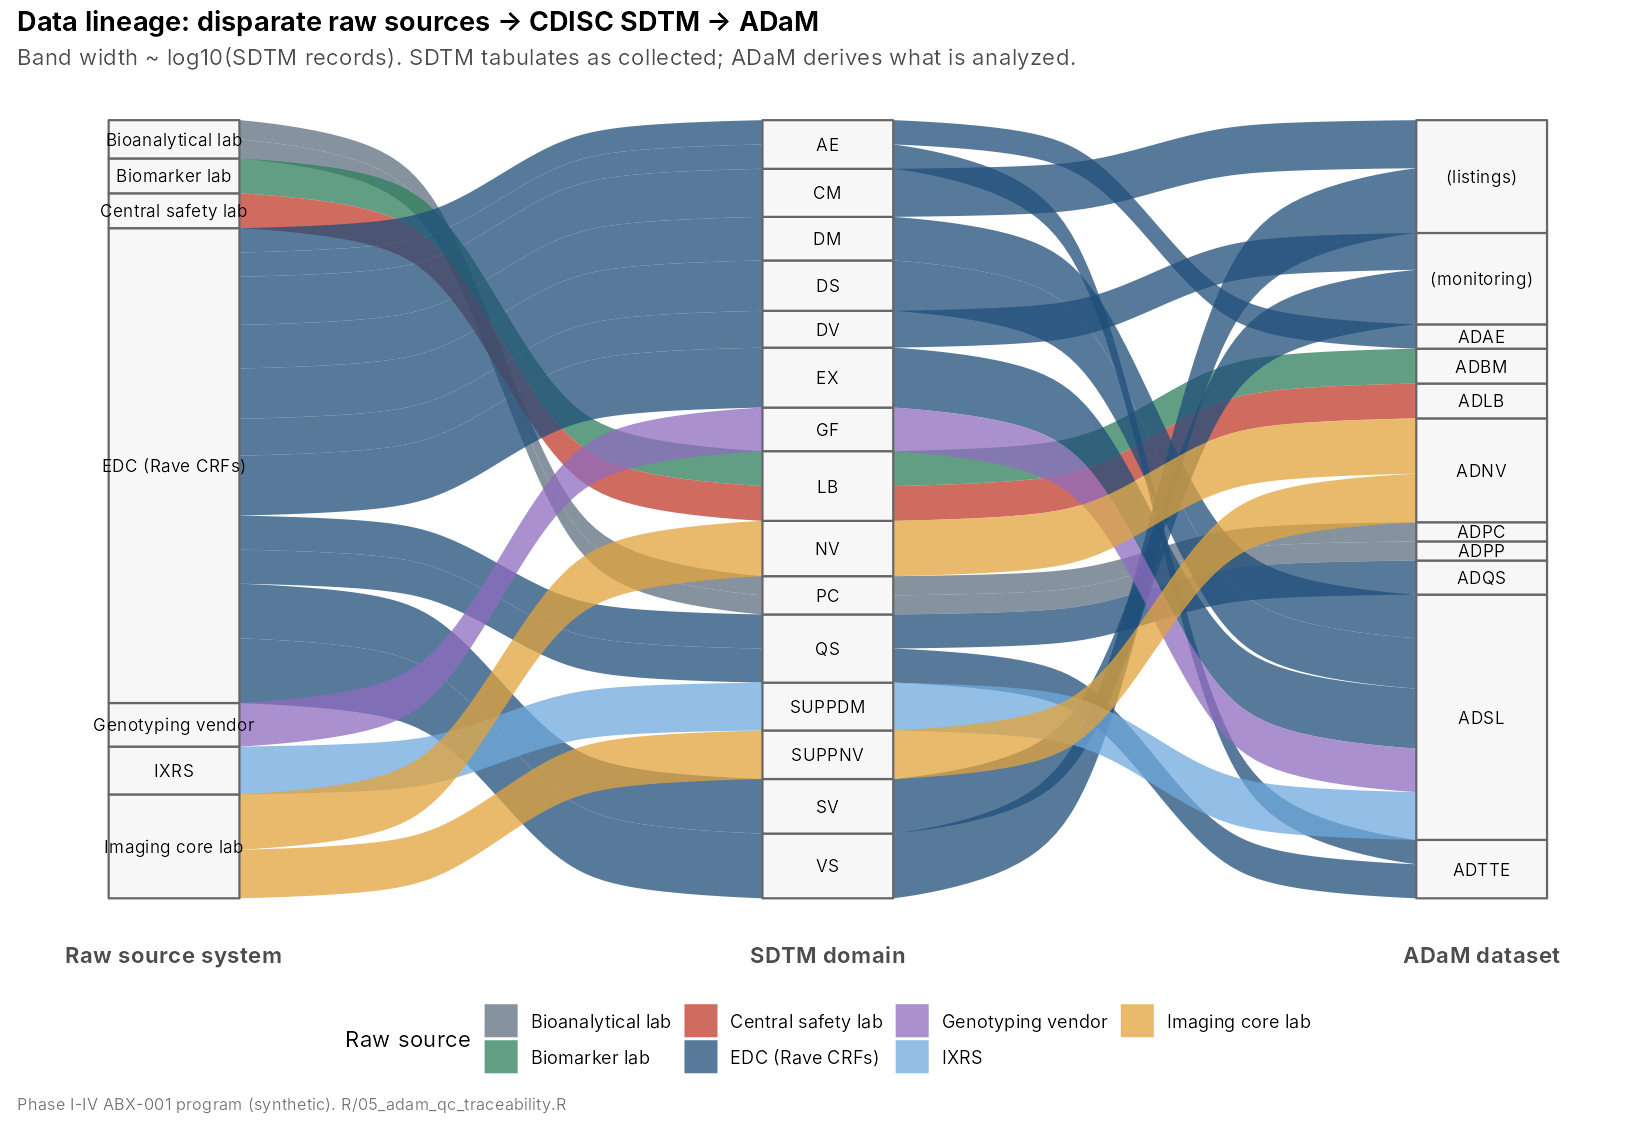

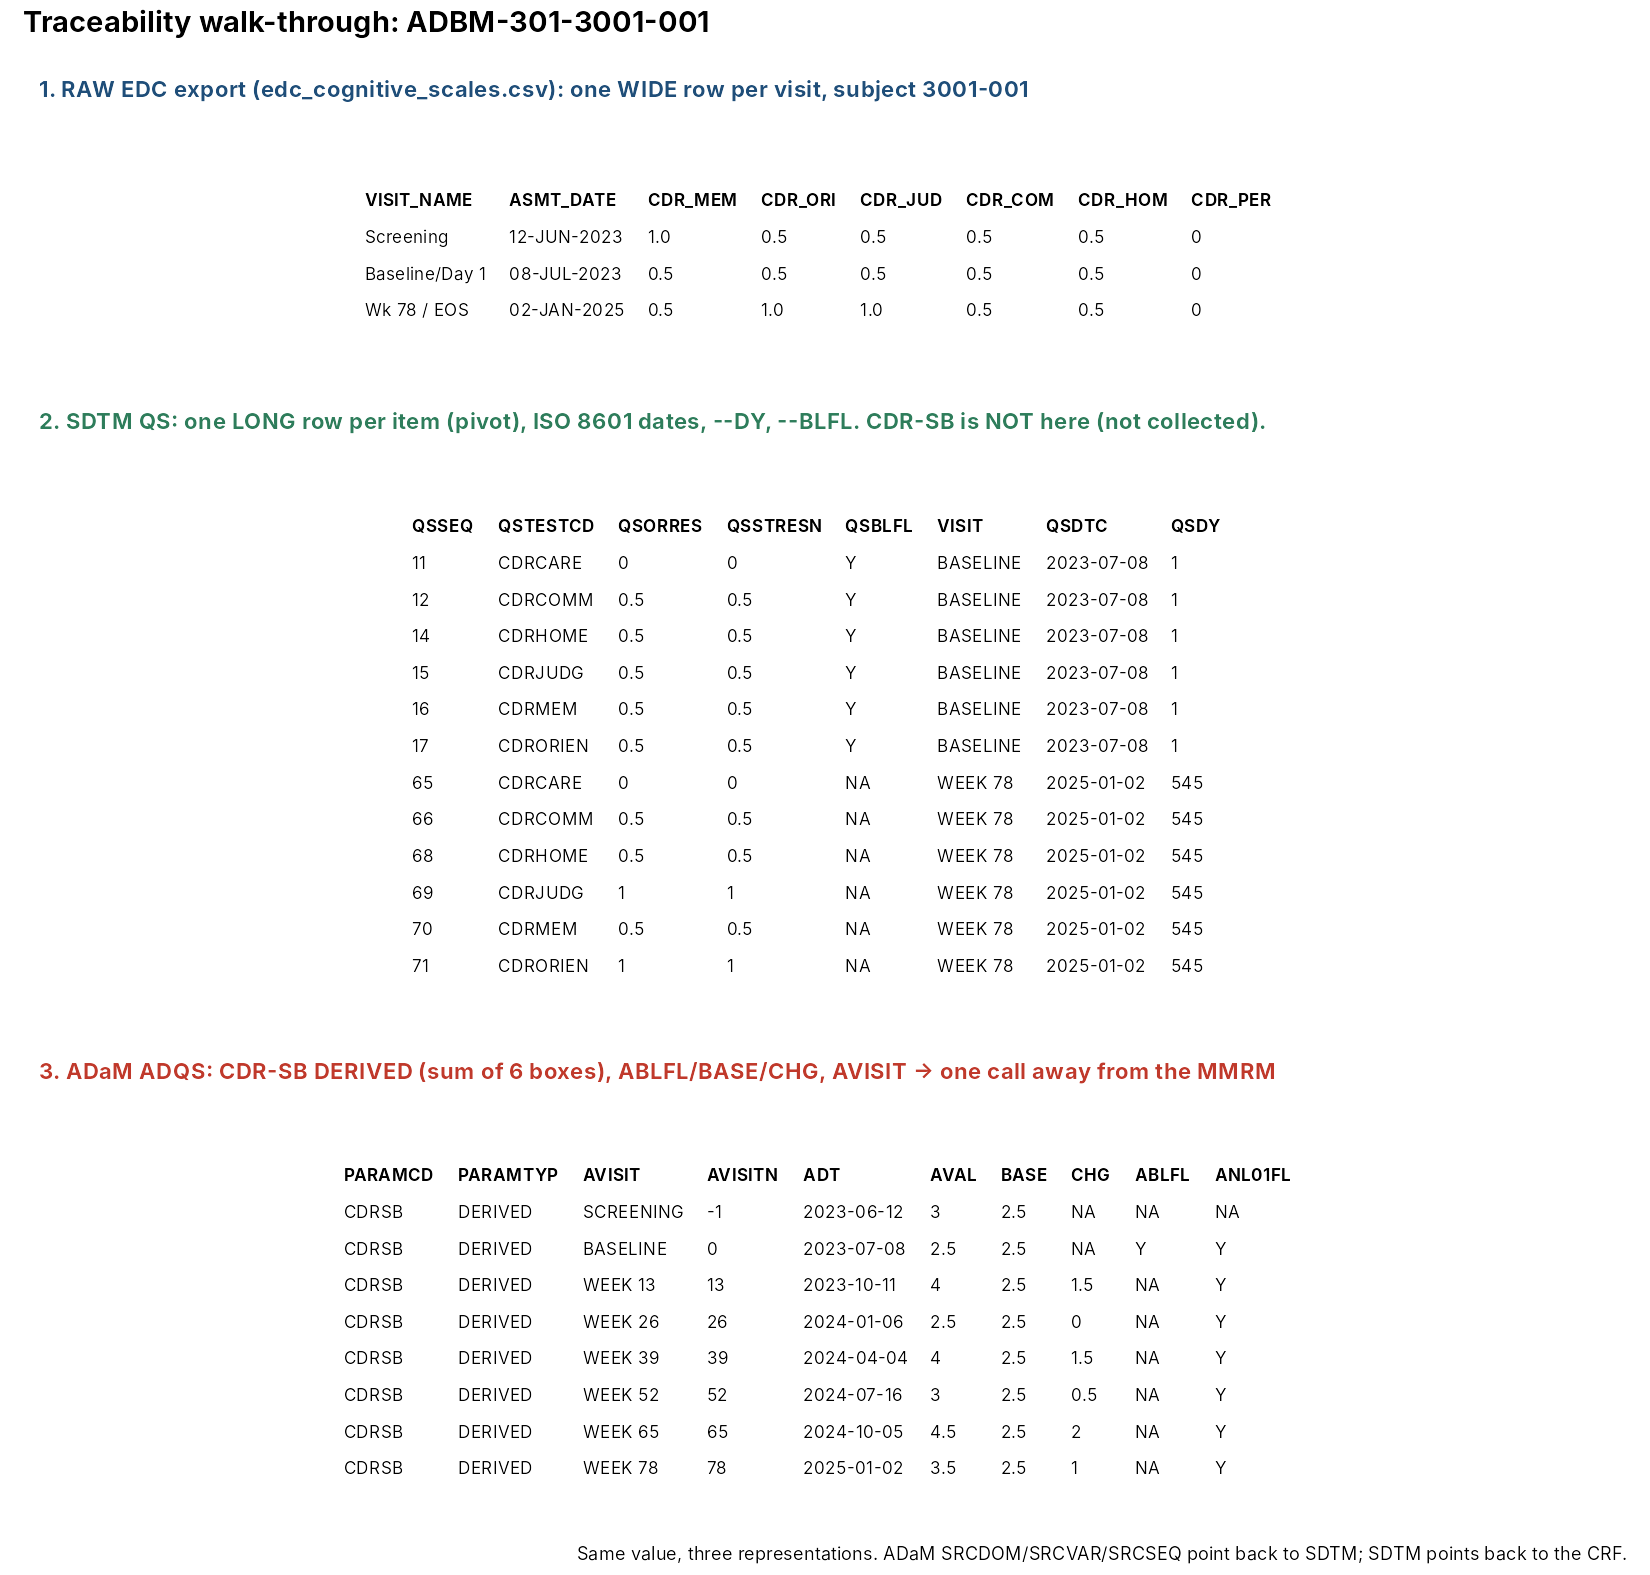

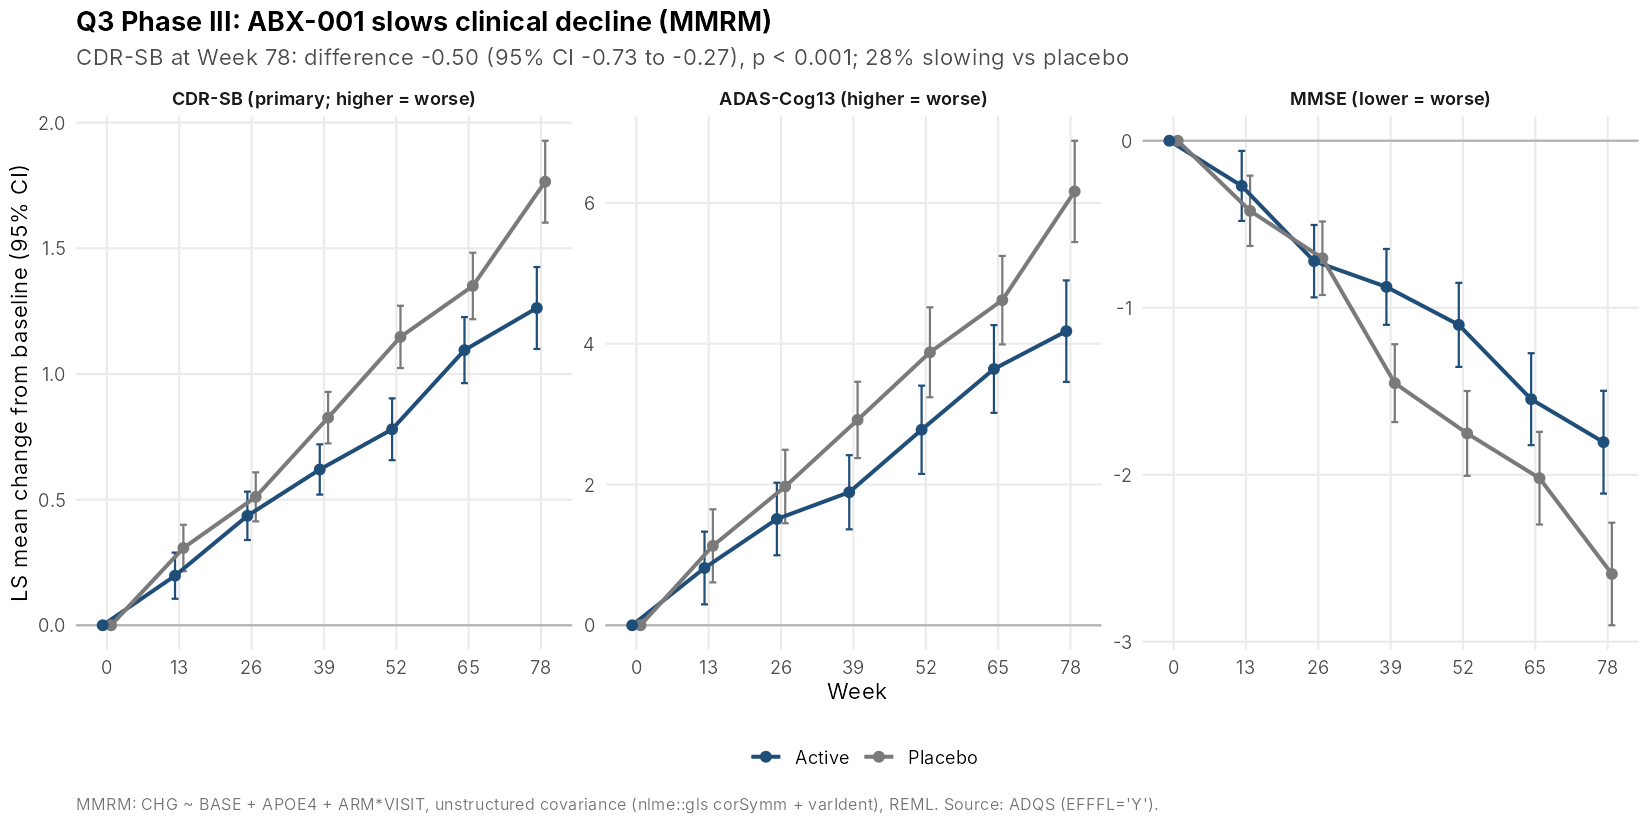

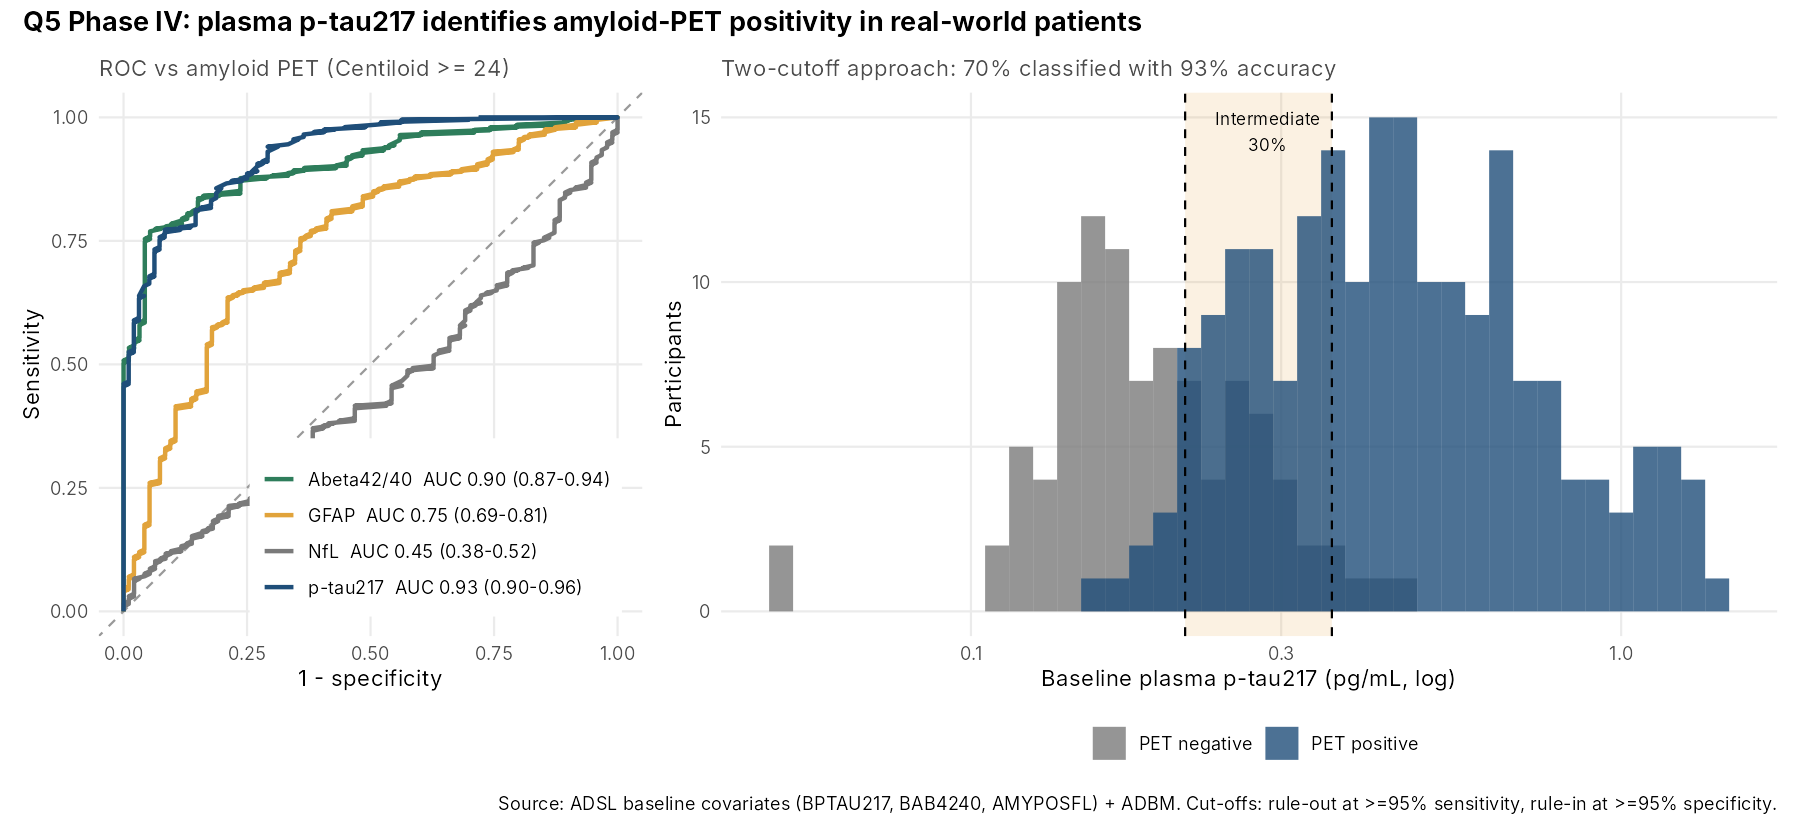

In [11]:
cat(paste(readLines(file.path(ROOT, "output", "key_results.json")), collapse = "\n"))
for (f in c("01_data_lineage_alluvial.png", "04_traceability_example.png", "08_phase3_cdrsb_mmrm.png", "12_phase4_roc_ptau217_vs_pet.png"))
  IRdisplay::display_png(file = file.path(DIR_FIG, f))